        # What does "peak online hours up 24 percent" stand for, and what happened to six drivers we can count by hand?

        Week 4, Monday, chapter 1 of 3. Level 1: read the ticket, say what the number stands for,
        and count it by hand on twelve rows of the case's own data.

**The ticket. Uber, Hyderabad, the driver app's peak-hour earnings guarantee.**

> *Illustrative case: the company is real, the situation and the data are synthetic, built for this class.*

On Monday 31 August 2026 the Hyderabad city team launched a peak-hour earnings guarantee for
enrolled drivers: a driver who stays online through a whole peak window (two windows a day, each
three hours long, set by the city team) is guaranteed a floor of Rs 300 per peak online hour, and
Uber pays the gap between the driver's trip earnings in the window and the floor as a top-up. The
goal written in the launch note was "more drivers on the road at peak, so riders are picked up
faster". The terms are synthetic.

Six weeks after the launch (the weeks beginning 31 August to 5 October 2026) against the six weeks
before (the weeks beginning 20 July to 24 August 2026):

| Measure | Before | After | Change |
|---|---|---|---|
| Peak online hours, all enrolled drivers | 118,000 | 146,300 | up 24 percent |
| Completed peak trips | 224,200 | 230,900 | up 3 percent |
| Trips per peak online hour | 1.90 | 1.58 | 1.9 to 1.6 |
| Offers accepted over offers shown, at peak | 0.86 | 0.73 | down 13 points |
| Accepted trips the driver then cancelled, share | 0.04 | 0.09 | up 5 points |
| Peak online hours with no completed trip, share | 0.22 | 0.38 | up 16 points |
| Median rider wait at peak, minutes | 4.8 | 4.6 | barely moved |
| Rider requests at peak that went unfulfilled, share | 0.11 | 0.10 | barely moved |
| Top-up paid | Rs 0 | Rs 1.9 crore | |

**Data the analyst has.**

| Table | Columns | Rows |
|---|---|---|
| `drivers` | `driver_id`, `home_zone`, `joined_month`, `enrolled` | 1,200 drivers, 140 of them joined after the launch |
| `driver_weeks` | `driver_id`, `week_start`, `zone_mode` (the zone where most online time was), `peak_online_hours`, `peak_offers`, `peak_accepted`, `peak_driver_cancels`, `peak_trips`, `peak_hours_no_trip`, `peak_bookings_rs`, `topup_rs`, `offpeak_trips` | one row for every driver on the app that week, twelve weeks |
| `zone_weeks` | `zone`, `week_start`, `peak_requests`, `peak_fulfilled`, `median_wait_min` | 12 zones by twelve weeks |

A rider's request that one driver declines is offered to the next driver, so `driver_weeks` counts
offers (every time a driver was shown a request) and `zone_weeks` counts rider requests.

**The ask, due Friday, to the city head.** Is the scheme working? Which metric should it pay for? Is
anyone gaming it, and how would we know?

**Known caveats.** The monsoon ended inside the after window. 140 drivers joined after the launch.
The app logs a driver as online whenever the driver app is open and the driver is marked available,
wherever the phone is. The three outer zones (Shamshabad, Rajendranagar, Patancheru) get few
requests at any hour. Drivers can be online on more than one platform at once, and Uber cannot see
the other platforms.

        **Who needs the answer.** The Hyderabad city head decides on Friday whether the scheme is
        working and whether to extend it. If "hours up 24 percent" is read as "more riders served"
        and it is not, the same top-up goes to two more cities.

        **The questions on the way.**

        1. What happens to a number that stands in for the goal once people are paid for it?
        2. What did six drivers' hours and trips do between one week before and one week after?
        3. What is trips per peak online hour on those twelve rows, before and after?
        4. Which drivers moved it, and why do the six fall further than the city?

## What happens to a number that stands in for the goal once people are paid for it?

A **proxy** is a number that stands in for the thing somebody wants. A canteen, with
**invented numbers**, wants plates served to hungry diners and pays its servers per token
printed, because tokens are easy to count. Tokens go from 200 to 400 a day while plates stay
at 200, because each plate now gets two tokens.

**Predict before you run.** What does tokens per plate do? a) stays at 1.0, since plates did
not change; b) rises to 2.0, since every plate now carries two tokens; c) falls to 0.5;
d) cannot be told without the menu.

This cell sets up the notebook and draws the canteen's two numbers side by side.

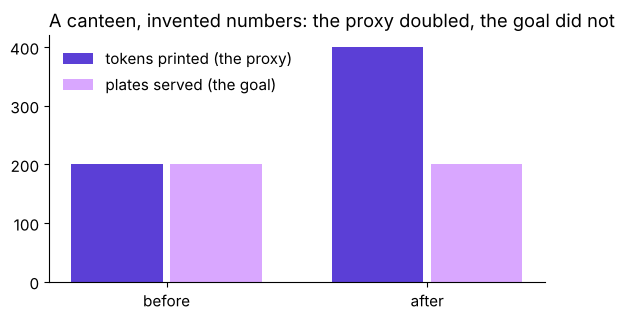

,day,tokens,plates,tokens_per_plate
0,before,200,200,1.0
1,after,400,200,2.0


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

def check(name, ok):
    print("PASS" if ok else "FAIL", name)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
INK, VIOLET, ROSE, LAV, MUTED = "#1A0F5C", "#5B3FD6", "#D63A6A", "#D9A7FF", "#6B6690"

canteen = pd.DataFrame({"day": ["before", "after"], "tokens": [200, 400], "plates": [200, 200]})
canteen["tokens_per_plate"] = canteen["tokens"] / canteen["plates"]
fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.bar([0, 1], canteen["tokens"], width=0.35, color=VIOLET, label="tokens printed (the proxy)")
ax.bar([0.38, 1.38], canteen["plates"], width=0.35, color=LAV, label="plates served (the goal)")
ax.set_xticks([0.19, 1.19], ["before", "after"])
ax.set_title("A canteen, invented numbers: the proxy doubled, the goal did not", loc="left")
ax.legend(frameon=False)
plt.show()
canteen

**What happened.** The answer is b: tokens per plate went from 1.0 to 2.0 and not one more
diner ate. That is the **proxy test**: could a team hit this number while the thing it
stands for got worse, or stayed the same? The ticket's "peak online hours" counts an hour
whenever the driver app is open, so it can fail the same test on the road.

## What did six drivers' hours and trips do between one week before and one week after?

The twelve rows are six drivers, A to F, each in two weeks: the week beginning 10 August 2026
(before the launch) and the week beginning 21 September 2026 (after). This cell keeps those
twelve driver-weeks out of `driver_weeks`.

In [2]:
dw = pd.read_csv("../data/C2_W04_D01_driver_weeks_STUDENT.csv")
names = {"d_0001": "A", "d_0002": "B", "d_0003": "C", "d_0004": "D", "d_0881": "E", "d_0882": "F"}
twelve = dw[dw["driver_id"].isin(names) & dw["week_start"].isin(["2026-08-10", "2026-09-21"])].copy()
twelve["driver"] = twelve["driver_id"].map(names)
twelve["week"] = twelve["week_start"].map({"2026-08-10": "before", "2026-09-21": "after"})
twelve = twelve.sort_values(["driver", "week"], ascending=[True, False])
twelve[["driver", "week", "zone_mode", "peak_online_hours", "peak_offers", "peak_accepted", "peak_trips"]]

,driver,week,zone_mode,peak_online_hours,peak_offers,peak_accepted,peak_trips
3180,A,before,Jubilee Hills,10,24,21,21
9588,A,after,Jubilee Hills,11,25,22,22
3181,B,before,Banjara Hills,9,20,17,17
9589,B,after,Banjara Hills,10,21,18,18
3182,C,before,Gachibowli,11,25,22,22
9590,C,after,Gachibowli,12,26,23,23
3183,D,before,Madhapur,10,22,19,19
9591,D,after,Madhapur,11,23,20,20
4060,E,before,Shamshabad,10,21,18,18
10468,E,after,Shamshabad,16,14,4,3


**Predict before you run.** On these six drivers, what happens to trips per peak online hour
between the two weeks? a) holds near 1.9; b) falls to about 1.6, as the city's did; c) falls
to about 1.2; d) rises above 2.0.

This cell adds up the hours and the trips in each week, then divides the two sums.

In [3]:
totals = twelve.groupby("week")[["peak_online_hours", "peak_trips"]].sum().loc[["before", "after"]]
totals["trips_per_hour"] = (totals["peak_trips"] / totals["peak_online_hours"]).round(2)
totals

,peak_online_hours,peak_trips,trips_per_hour
week,,,
before,60,114,1.90
after,74,88,1.19


**What happened.** The answer is c. The six drivers logged 60 hours and 114 trips before,
74 hours and 88 trips after: hours up 23 percent, trips down 23 percent, and trips per peak
online hour from 1.90 to 1.19. The city fell to 1.58, and the six fall further because they
were chosen to show the mechanism: two of them, E and F, logged hours with almost no trips,
a third of this sample. How common such drivers are in the city is chapter 2's question.

## Which drivers moved the ratio, and in which direction?

This cell takes each driver's own trips per hour in both weeks and draws one line per driver.

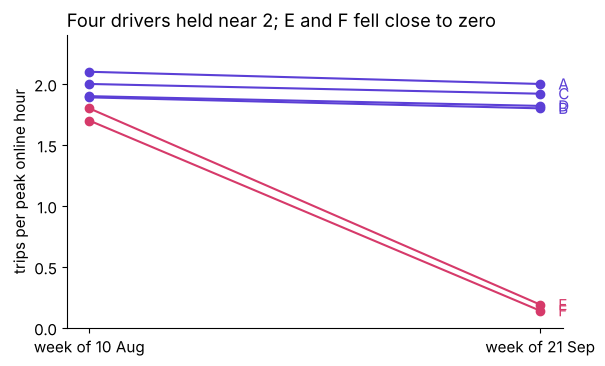

week,before,after
driver,,
A,2.10,2.00
B,1.89,1.80
C,2.00,1.92
D,1.90,1.82
E,1.80,0.19
F,1.70,0.14


In [4]:
wide = twelve.pivot(index="driver", columns="week", values=["peak_online_hours", "peak_trips"])
rate = (wide["peak_trips"] / wide["peak_online_hours"]).round(2)[["before", "after"]]
fig, ax = plt.subplots(figsize=(6.4, 3.8))
for driver, row in rate.iterrows():
    colour = ROSE if driver in "EF" else VIOLET
    ax.plot([0, 1], [row["before"], row["after"]], marker="o", color=colour)
    ax.text(1.04, row["after"], driver, color=colour, va="center")
ax.set_xticks([0, 1], ["week of 10 Aug", "week of 21 Sep"])
ax.set_ylim(0, 2.4)
ax.set_ylabel("trips per peak online hour")
ax.set_title("Four drivers held near 2; E and F fell close to zero", loc="left")
plt.show()
rate

**What happened.** A to D held between 1.80 and 2.10 trips an hour. E went from 10 hours and
18 trips to 16 hours and 3 trips, accepting 4 of the 14 offers it was shown; F went from 10
hours and 17 trips to 14 hours and 2 trips, accepting 3 of 12. Both sit in outer zones
(Shamshabad and Rajendranagar), where riders ask for few trips at any hour. Their hours went
up and their trips nearly vanished: the proxy rose while the thing it stands for fell.

This cell draws the six drivers' hours and trips as two pairs of bars, the picture the
hand count makes.

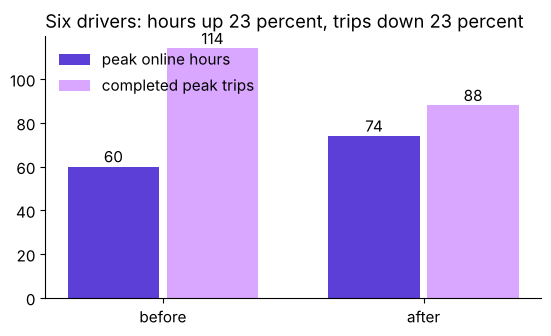

In [5]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.bar([0, 1], totals["peak_online_hours"], width=0.35, color=VIOLET, label="peak online hours")
ax.bar([0.38, 1.38], totals["peak_trips"], width=0.35, color=LAV, label="completed peak trips")
for x, v in zip([0, 1, 0.38, 1.38], list(totals["peak_online_hours"]) + list(totals["peak_trips"])):
    ax.text(x, v + 2, str(v), ha="center")
ax.set_xticks([0.19, 1.19], ["before", "after"])
ax.set_title("Six drivers: hours up 23 percent, trips down 23 percent", loc="left")
ax.legend(frameon=False, loc="upper left")
plt.show()

This cell checks the claims the chapter makes about its own numbers.

In [6]:
check("the canteen's tokens per plate went from 1.0 to 2.0", list(canteen["tokens_per_plate"]) == [1.0, 2.0])
check("the twelve rows are six drivers in two weeks", len(twelve) == 12 and twelve["driver"].nunique() == 6)
check("hours 60 before and 74 after", list(totals["peak_online_hours"]) == [60, 74])
check("trips 114 before and 88 after", list(totals["peak_trips"]) == [114, 88])
check("trips per peak online hour 1.90 before and 1.19 after", list(totals["trips_per_hour"]) == [1.90, 1.19])
check("E and F fell below 0.25 trips an hour after the launch", (rate.loc[["E", "F"], "after"] < 0.25).all())

PASS the canteen's tokens per plate went from 1.0 to 2.0
PASS the twelve rows are six drivers in two weeks
PASS hours 60 before and 74 after
PASS trips 114 before and 88 after
PASS trips per peak online hour 1.90 before and 1.19 after
PASS E and F fell below 0.25 trips an hour after the launch


## What does chapter 1 answer?

1. A paid proxy drifts: the canteen's tokens doubled while plates stayed at 200 (invented).
2. The six drivers' hours rose from 60 to 74 while their trips fell from 114 to 88.
3. Trips per peak online hour on the twelve rows fell from 1.90 to 1.19.
4. E and F moved it: their hours rose while their trips fell to 3 and 2. The six fall further
   than the city's 1.58 because they were chosen to show the mechanism.

**The check a senior analyst runs before trusting a rate.** Read its baseline (1.90 before),
its denominator (hours the app was open, which a driver controls) and the evidence that the
thing it stands for moved (trips rose only 3 percent across the city).

**In the interview.** [S] How would you measure the success of a new feature? A hire-grade
answer starts from what the feature is for and names a number that cannot rise while that
thing gets worse. Notebook 02 runs the same count on all 12,860 driver-weeks.